# 03 – Frame scoring

Scores every text (chatbot answers and news chunks) on the six frames with the keyword lexicon in `dataset/frames/frame_keywords.json` (v1.1, frozen before any hypothesis test), then computes the **normalised frame entropy** used by H1 and H2 and the frame distributions used by H3.
This notebook produces the scores. The hypothesis tests themselves belong in the next notebook.

**Method (for the report)**
- **Matching:** spaCy lemmas, hyphens turned into spaces first (start-up, high-stakes), `PhraseMatcher` on lemmas, **longest match wins** (`filter_spans`) so a phrase and its parts never double count. Each term belongs to one frame.
- **Length rule:** every text is cut to its first 300 words (team decision), chatbot and news alike.
- **Frame share** = hits in a frame / all hits in the text. **Normalised entropy** = Shannon entropy of the six shares divided by log 6, so 0 = all emphasis on one frame and 1 = perfectly even. Texts with fewer than `MIN_HITS` = 5 hits are not scored (entropy of a handful of hits is unstable).
- **Robustness variants**, all reported next to the main result: (a) without the 27 *ambiguous* terms, (b) without terms that appear in the answer's own prompt (chatbot only: stops question wording from counting as emphasis), (c) without the governance frame (the topic itself is regulation, so governance may sit near its ceiling in every text).
- **Jurisdiction terms** (GDPR, AI Act, FTC, Congress, ...) are *not* frames. They are counted separately so the region comparison (H3) is not circular.
- **Scores only are saved** (no article text), so the output files are safe to commit.

In [1]:
import json, re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from framescore import nlp, norm, lem, cut, Lexicon, find_hits as _find_hits, count_vector, entropy, MAX_WORDS, MIN_HITS

SEED = 42
rng = np.random.default_rng(SEED)

CFG = json.load(open("config.json"))          # all data paths live in config.json
LEXICON, ANSWERS, PROMPTS = Path(CFG["lexicon_json"]), Path(CFG["answers_jsonl"]), Path(CFG["prompts_csv"])
NEWS_CSV = Path(CFG["news_corpus_csv"])       # git-ignored (article text)
OUT = Path(CFG["analysis_dir"]); OUT.mkdir(parents=True, exist_ok=True)

CHATBOTS = ["llama3.1:8b", "qwen3.5:9b"]
WORDINGS = ["neutral", "leaning_for", "leaning_against"]
TOPIC_TO_FRAME = {"innovation": "innovation_opportunity", "risk_safety": "risk_safety", "governance": "regulation_governance",
                  "rights_privacy": "rights_privacy", "economy_labour": "economy_labour", "misinformation": "misinformation_integrity"}

## 1. Lexicon and matcher
The scorer lives in `framescore.py` and is shared by every notebook, so there is exactly one implementation.

In [2]:
LEX = Lexicon(LEXICON)
lex, FRAMES, AMBIGUOUS = LEX.raw, LEX.frames, LEX.ambiguous
matcher, owner, jur_matcher, jur_owner = LEX.matcher, LEX.owner, LEX.jur_matcher, LEX.jur_owner
print("lexicon version", LEX.version)
print({f: sum(1 for o in owner.values() if o == f) for f in FRAMES}, "| ambiguous:", len(AMBIGUOUS))

lexicon version 1.1
{'innovation_opportunity': 28, 'risk_safety': 33, 'regulation_governance': 35, 'rights_privacy': 32, 'economy_labour': 48, 'misinformation_integrity': 32} | ambiguous: 27


## 2. Scoring functions
`find_hits` returns, for each text, the list of matched lemma phrases with their frame. Everything else (variants, entropy) is computed from that list, so the variants cannot drift apart.

In [3]:
def find_hits(texts, m=None, own=None):
    return _find_hits(texts, m or matcher, own or owner)

def counts(hit_lists, drop=frozenset(), frames=None):
    frames = frames or FRAMES
    return pd.DataFrame([count_vector(h, frames, drop) for h in hit_lists], columns=frames)

def score_table(meta, hit_lists, echo=None):
    """One row per text: counts per frame, totals and entropy for the main run and each robustness variant."""
    t = meta.reset_index(drop=True).copy()
    main = counts(hit_lists)
    t[[f"hits_{f}" for f in FRAMES]] = main.values
    t["hits_total"] = main.sum(axis=1)
    t["entropy"] = main.apply(entropy, axis=1)
    t["entropy_no_ambiguous"] = counts(hit_lists, drop=AMBIGUOUS).apply(entropy, axis=1)
    noext = [f for f in FRAMES if f != "regulation_governance"]
    t["entropy_no_governance"] = counts(hit_lists, frames=noext).apply(entropy, axis=1)
    if echo is not None:
        t["entropy_no_prompt_echo"] = [entropy(counts([h], drop=e).iloc[0]) for h, e in zip(hit_lists, echo)]
    t["hits_per_100w"] = 100 * t["hits_total"] / t["n_words"]
    return t

## 3. Chatbot answers

In [4]:
ans = pd.read_json(ANSWERS, lines=True)
ans = ans[ans["chatbot"].isin(CHATBOTS)].reset_index(drop=True)
prompts = pd.read_csv(PROMPTS).set_index("prompt_id")

ans["text_cut"] = ans["answer"].map(cut)
ans["n_words"] = ans["text_cut"].map(lambda t: len(t.split()))

hits_a = find_hits(ans["text_cut"])
# terms found in each answer's own prompt (ignored in the prompt-echo variant)
prompt_terms = {pid: {l for _, l in h} for pid, h in zip(prompts.index, find_hits(prompts["prompt"]))}
echo_a = [prompt_terms[p] for p in ans["prompt_id"]]

meta_a = ans[["prompt_id", "question_id", "topic_frame", "wording", "chatbot", "replicate", "n_words"]]
sc_a = score_table(meta_a, hits_a, echo_a)
sc_a.to_csv(OUT / "frame_scores_chatbot.csv", index=False)
print(len(sc_a), "answers scored;", int(sc_a["entropy"].isna().sum()), "below", MIN_HITS, "hits (entropy not defined)")
sc_a.groupby("chatbot")[["n_words", "hits_total", "hits_per_100w", "entropy"]].mean().round(2)

216 answers scored; 0 below 5 hits (entropy not defined)


,n_words,hits_total,hits_per_100w,entropy
chatbot,,,,
llama3.1:8b,223.22,15.58,6.96,0.62
qwen3.5:9b,287.34,26.35,9.17,0.76


## 4. Chatbot results
Replicates of one prompt are averaged first (the unit is the prompt, n = 18 per chatbot × wording); bootstrap intervals resample prompts.

In [5]:
VARIANTS = ["entropy", "entropy_no_ambiguous", "entropy_no_prompt_echo", "entropy_no_governance"]

def boot_ci(x, n=5000):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    if len(x) < 2: return (np.nan, np.nan)
    return tuple(np.percentile(rng.choice(x, (n, len(x))).mean(axis=1), [2.5, 97.5]))

per_prompt = sc_a.groupby(["chatbot", "wording", "question_id", "topic_frame"], as_index=False)[VARIANTS].mean()
rows = []
for (bot, w), g in per_prompt.groupby(["chatbot", "wording"]):
    for v in VARIANTS:
        lo, hi = boot_ci(g[v]); rows.append({"chatbot": bot, "wording": w, "variant": v, "n_prompts": g[v].notna().sum(),
                                             "mean": g[v].mean(), "ci_low": lo, "ci_high": hi})
ent_a = pd.DataFrame(rows)
ent_a.to_csv(OUT / "entropy_chatbot_by_wording.csv", index=False)
ent_a[ent_a["variant"] == "entropy"].round(3)

,chatbot,wording,variant,n_prompts,mean,ci_low,ci_high
0,llama3.1:8b,leaning_against,entropy,18,0.623,0.582,0.663
4,llama3.1:8b,leaning_for,entropy,18,0.623,0.563,0.681
8,llama3.1:8b,neutral,entropy,18,0.628,0.592,0.663
12,qwen3.5:9b,leaning_against,entropy,18,0.751,0.722,0.781
16,qwen3.5:9b,leaning_for,entropy,18,0.761,0.708,0.803
20,qwen3.5:9b,neutral,entropy,18,0.768,0.745,0.790


In [6]:
# Entropy under every variant, side by side
ent_a.pivot_table(index=["chatbot", "wording"], columns="variant", values="mean").round(3)[VARIANTS]

variant                      entropy  entropy_no_ambiguous  \
chatbot     wording                                          
llama3.1:8b leaning_against    0.623                 0.575   
            leaning_for        0.623                 0.532   
            neutral            0.628                 0.553   
qwen3.5:9b  leaning_against    0.751                 0.725   
            leaning_for        0.761                 0.733   
            neutral            0.768                 0.719   

variant                      entropy_no_prompt_echo  entropy_no_governance  
chatbot     wording                                                         
llama3.1:8b leaning_against                   0.618                  0.561  
            leaning_for                       0.678                  0.523  
            neutral                           0.648                  0.516  
qwen3.5:9b  leaning_against                   0.746                  0.690  
            leaning_for                       0.770                  0.704  
            neutral                           0.777                  0.707

In [7]:
# Frame mix (share of hits) per wording and per topic_frame. Report this, not only one pooled entropy figure.
HC = [f"hits_{f}" for f in FRAMES]
def mix(df, by):
    s = df.groupby(by)[HC].sum(); return s.div(s.sum(axis=1), axis=0).set_axis(FRAMES, axis=1).round(3)

mix_wording = mix(sc_a, ["chatbot", "wording"]); mix_topic = mix(sc_a, ["topic_frame"])
mix_wording.to_csv(OUT / "frame_mix_chatbot_by_wording.csv"); mix_topic.to_csv(OUT / "frame_mix_chatbot_by_topic.csv")
display(mix_wording)

share_own = sc_a.assign(own=[row[f"hits_{TOPIC_TO_FRAME[row.topic_frame]}"] / row.hits_total
                             for _, row in sc_a.iterrows()]).groupby("topic_frame")["own"].mean().round(2)
print("Share of hits in the question's own frame (answers are not just echoing the question if this is well below 1):")
print(share_own.to_dict())

innovation_opportunity  risk_safety  \
chatbot     wording                                                
llama3.1:8b leaning_against                   0.241        0.193   
            leaning_for                       0.168        0.253   
            neutral                           0.252        0.244   
qwen3.5:9b  leaning_against                   0.183        0.244   
            leaning_for                       0.165        0.256   
            neutral                           0.176        0.283   

                             regulation_governance  rights_privacy  \
chatbot     wording                                                  
llama3.1:8b leaning_against                  0.280           0.081   
            leaning_for                      0.218           0.125   
            neutral                          0.233           0.085   
qwen3.5:9b  leaning_against                  0.324           0.048   
            leaning_for                      0.276           0.089   
            neutral                          0.307           0.063   

                             economy_labour  misinformation_integrity  
chatbot     wording                                                    
llama3.1:8b leaning_against           0.145                     0.060  
            leaning_for               0.168                     0.069  
            neutral                   0.133                     0.053  
qwen3.5:9b  leaning_against           0.168                     0.033  
            leaning_for               0.124                     0.090  
            neutral                   0.109                     0.063

Share of hits in the question's own frame (answers are not just echoing the question if this is well below 1):
{'economy_labour': 0.44, 'governance': 0.41, 'innovation': 0.31, 'misinformation': 0.37, 'rights_privacy': 0.4, 'risk_safety': 0.48}


In [8]:
# Does entropy depend on length? (H1 compares at matched length, so this must be checked)
ok = sc_a.dropna(subset=["entropy"])
print("Spearman, words vs entropy:", tuple(round(x, 2) for x in spearmanr(ok["n_words"], ok["entropy"])))
print("Spearman, words vs total hits:", tuple(round(x, 2) for x in spearmanr(sc_a["n_words"], sc_a["hits_total"])))

Spearman, words vs entropy: (np.float64(0.5), np.float64(0.0))
Spearman, words vs total hits: (np.float64(0.69), np.float64(0.0))


## 5. News chunks (runs only when `data/news_clean.csv` exists)

In [9]:
sc_n = None
if not NEWS_CSV.exists():
    print("No", NEWS_CSV, "yet - skipping news. Rerun this notebook when the corpus is built.")
else:
    news = pd.read_csv(NEWS_CSV, keep_default_na=False)
    news["text_cut"] = news["text"].map(cut)
    news["n_words"] = news["text_cut"].map(lambda t: len(t.split()))
    hits_n = find_hits(news["text_cut"])
    meta_n = news[["doc_id", "outlet", "region", "month", "quarter", "n_words"]] if "doc_id" in news else news[["outlet", "region", "month", "n_words"]]
    sc_n = score_table(meta_n, hits_n)
    sc_n.to_csv(OUT / "frame_scores_news.csv", index=False)
    print(len(sc_n), "news chunks scored;", int(sc_n["entropy"].isna().sum()), "below", MIN_HITS, "hits;",
          "words after cut: median", int(sc_n["n_words"].median()), "| under 300:", int((sc_n["n_words"] < MAX_WORDS).sum()))
    display(sc_n.groupby("region")[["n_words", "hits_total", "hits_per_100w", "entropy", "entropy_no_ambiguous", "entropy_no_governance"]].agg(["mean"]).round(2))
    display(mix(sc_n, ["region"]))

    # Jurisdiction terms: counted, not scored (kept out of the frames so H3 is not circular)
    jur = find_hits(news["text_cut"], jur_matcher, jur_owner)
    news["jurisdiction_hits_per_100w"] = [100 * len(h) / max(w, 1) for h, w in zip(jur, news["n_words"])]
    print("Jurisdiction-term hits per 100 words by region:", news.groupby("region")["jurisdiction_hits_per_100w"].mean().round(2).to_dict())

420 news chunks scored; 108 below 5 hits; words after cut: median 300 | under 300: 7


,n_words,hits_total,hits_per_100w,entropy,entropy_no_ambiguous,entropy_no_governance
,mean,mean,mean,mean,mean,mean
region,,,,,,
EU,299.77,8.65,2.89,0.59,0.54,0.52
Other,300.00,7.67,2.56,0.47,0.47,0.42
UK,297.37,8.89,3.00,0.55,0.47,0.50
US,299.00,8.01,2.68,0.53,0.45,0.48


,innovation_opportunity,risk_safety,regulation_governance,rights_privacy,economy_labour,misinformation_integrity
region,,,,,,
EU,0.121,0.275,0.224,0.100,0.197,0.082
Other,0.143,0.308,0.162,0.053,0.281,0.054
UK,0.166,0.265,0.176,0.108,0.210,0.075
US,0.112,0.282,0.175,0.103,0.264,0.065


Jurisdiction-term hits per 100 words by region: {'EU': 0.33, 'Other': 0.07, 'UK': 0.11, 'US': 0.41}


## 6. Chatbot vs news (descriptive; the tests come in the next notebook)

In [10]:
if sc_n is not None:
    a = sc_a.assign(group="chatbot: " + sc_a["chatbot"]); n = sc_n.assign(group="news: " + sc_n["region"])
    comp = pd.concat([a, n])
    display(comp.groupby("group")[["n_words", "hits_per_100w"] + VARIANTS[:2] + ["entropy_no_governance"]].mean().round(3))

,n_words,hits_per_100w,entropy,entropy_no_ambiguous,entropy_no_governance
group,,,,,
chatbot: llama3.1:8b,223.222,6.961,0.625,0.550,0.535
chatbot: qwen3.5:9b,287.343,9.175,0.760,0.726,0.701
news: EU,299.768,2.885,0.586,0.537,0.518
news: Other,300.000,2.558,0.471,0.468,0.423
news: UK,297.366,3.004,0.554,0.469,0.500
news: US,299.000,2.682,0.529,0.453,0.475


## 7. Figure: frame mix per group

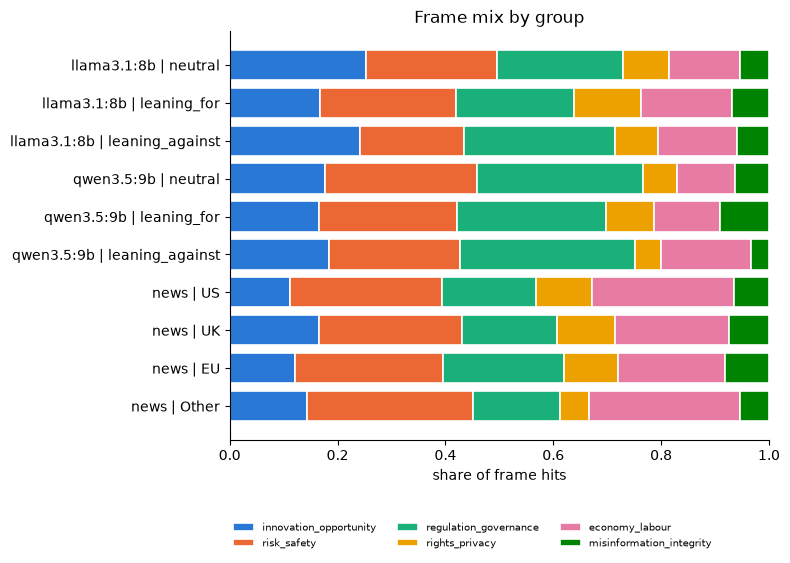

In [11]:
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]   # fixed order = FRAMES order
groups = {f"{b} | {w}": sc_a[(sc_a.chatbot == b) & (sc_a.wording == w)] for b in CHATBOTS for w in WORDINGS}
if sc_n is not None:
    groups.update({f"news | {r}": sc_n[sc_n.region == r] for r in ["US", "UK", "EU", "Other"] if (sc_n.region == r).any()})
shares = pd.DataFrame({g: d[HC].sum() / d[HC].sum().sum() for g, d in groups.items()}).T
shares.columns = FRAMES

fig, ax = plt.subplots(figsize=(8, 0.42 * len(shares) + 1.6))
left = np.zeros(len(shares))
for fr, col in zip(FRAMES, PALETTE):
    ax.barh(shares.index, shares[fr], left=left, color=col, edgecolor="white", linewidth=1.2, label=fr)
    left += shares[fr].values
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("share of frame hits")
ax.legend(ncol=3, fontsize=7.5, frameon=False, loc="upper center", bbox_to_anchor=(0.45, -0.18))
ax.spines[["top", "right"]].set_visible(False); ax.set_title("Frame mix by group")
fig.tight_layout(); fig.savefig(OUT / "frame_mix_by_group.png", dpi=200); plt.show()

## 8. Lexicon diagnostics
Which terms do the work, and which never fire? A frame whose hits come from one or two terms is a weak measure. Terms with no hits in the answers may still matter for news; do not drop them before the news corpus is scored.

In [12]:
def term_counts(hit_lists):
    return Counter(l for h in hit_lists for _, l in h)

tc = term_counts(hits_a)
diag = pd.DataFrame([{"frame": o, "term": t, "ambiguous": t in AMBIGUOUS, "hits_chatbot": tc.get(t, 0)} for t, o in owner.items()])
if sc_n is not None:
    tn = term_counts(hits_n); diag["hits_news"] = diag["term"].map(lambda t: tn.get(t, 0))
diag = diag.sort_values(["frame", "hits_chatbot"], ascending=[True, False])
diag.to_csv(OUT / "lexicon_term_counts.csv", index=False)

top_share = diag.groupby("frame").apply(lambda g: g["hits_chatbot"].head(3).sum() / max(g["hits_chatbot"].sum(), 1), include_groups=False).round(2)
print("Share of a frame's chatbot hits that come from its top 3 terms:", top_share.to_dict())
print("Terms with no chatbot hits:", (diag["hits_chatbot"] == 0).sum(), "of", len(diag))
diag.groupby("frame").head(5)

Share of a frame's chatbot hits that come from its top 3 terms: {'economy_labour': 0.31, 'innovation_opportunity': 0.57, 'misinformation_integrity': 0.43, 'regulation_governance': 0.3, 'rights_privacy': 0.42, 'risk_safety': 0.51}
Terms with no chatbot hits: 33 of 208


,frame,term,ambiguous,hits_chatbot,hits_news
134,economy_labour,market,True,87,107
129,economy_labour,economic,False,59,31
164,economy_labour,industry,True,49,134
131,economy_labour,competitive,False,38,12
142,economy_labour,worker,False,36,39
0,innovation_opportunity,innovation,False,224,63
24,innovation_opportunity,potential,True,161,72
22,innovation_opportunity,benefit,True,109,31
25,innovation_opportunity,progress,True,79,13
23,innovation_opportunity,beneficial,False,47,1


## 9. Tests (regression test for the casing bug)
**The bug (fixed):** spaCy lemmas of proper nouns keep their capitals (`EU`, `Congress`, `Trump`), and a sentence-initial common word that the tagger takes for a proper noun does too (`Transparency`). A lower-case pattern never matched those. The fix lower-cases the text (and the patterns) before matching; hyphens are normalised in the same function (`norm`), so there is one text path for both.
**What changed because of the fix:** the chatbot scores differ from the pre-fix reference in exactly one answer (Q09 `leaning_for`, Qwen, replicate 2, one extra `transparency` hit); news scores changed more (hits per 100 words 2.55 to 2.77, texts under 5 hits 124 to 108). The tests below fail loudly (the notebook stops) if matching ever becomes case-sensitive again.

In [13]:
import hashlib, glob

def lemmas_hit(text, m=matcher, own=owner):
    return sorted(find_hits([text], m, own)[0])

# 1. Named entities and multi-word terms are matched
sample = ("The EU and Congress said Trump backs the AI Act, with facial recognition limits and trade union rights. "
          "Transparency matters. A start-up faced high-stakes scrutiny from the European Union.")
jur = {l for _, l in lemmas_hit(sample, jur_matcher, jur_owner)}
fr  = {l for _, l in lemmas_hit(sample)}
assert {"eu", "congress", "trump", "ai act", "european union"} <= jur, jur
assert {"facial recognition", "trade union", "transparency", "start up", "high stake"} <= fr, fr
assert "union" not in fr and "european union" not in fr, "a bare 'union' must not match: it would count the European Union as labour"
print("1. named entities, multi-word terms and hyphen normalisation: OK")

# 2. Identical matches for upper, lower and title case (sample + real texts)
pool = [sample] + ans["text_cut"].sample(20, random_state=SEED).tolist()
if NEWS_CSV.exists():
    pool += pd.read_csv(NEWS_CSV, keep_default_na=False)["text"].map(cut).sample(20, random_state=SEED).tolist()
variants = {"as written": lambda t: t, "UPPER": str.upper, "lower": str.lower, "Title": str.title}
for name, fn in variants.items():
    for t in pool:
        assert lemmas_hit(fn(t)) == lemmas_hit(t.lower()), (name, t[:60])
        assert lemmas_hit(fn(t), jur_matcher, jur_owner) == lemmas_hit(t.lower(), jur_matcher, jur_owner), (name, t[:60])
print("2. identical frame and jurisdiction matches in", len(variants), "casings across", len(pool), "texts: OK")

# 3. Chatbot scores vs the pre-fix reference: exactly one documented row differs
ref = pd.read_csv(OUT / "reference" / "frame_scores_chatbot_before_case_fix.csv")
new = pd.read_csv(OUT / "frame_scores_chatbot.csv")
diff_rows = (ref.fillna(-9) != new.fillna(-9)).any(axis=1)
assert diff_rows.sum() == 1, f"{diff_rows.sum()} rows differ from the pre-fix reference, expected exactly 1"
r = new[diff_rows].iloc[0]; o = ref[diff_rows].iloc[0]
assert (r.prompt_id, r.chatbot, r.replicate) == ("Q09_leaning_for", "qwen3.5:9b", 2)
assert r.hits_total - o.hits_total == 1 and r.hits_regulation_governance - o.hits_regulation_governance == 1
print("3. chatbot scores: 215 of 216 rows identical to the pre-fix reference; the one change is +1 governance hit (transparency): OK")
print("   sha256 of the current chatbot score file (valid for lexicon", lex["version"] + "):", hashlib.sha256(Path(OUT / "frame_scores_chatbot.csv").read_bytes()).hexdigest()[:16])

# 4. Only one frame scorer exists: framescore.py. No notebook builds its own matcher.
PM = "Phrase" + "Matcher"      # built from parts so this cell does not match itself
users = {}
for f in sorted(glob.glob("*.ipynb")):
    src = "".join("".join(c["source"]) for c in json.load(open(f))["cells"] if c["cell_type"] == "code")
    users[f] = {"own matcher": (PM in src or PM[6:] + "(" in src), "imports framescore": "framescore" in src}
inv = pd.DataFrame(users).T
assert not inv["own matcher"].any(), "a notebook builds its own matcher: " + str(inv[inv["own matcher"]].index.tolist())
assert PM in open("framescore.py").read()
print("4. notebooks with their own matcher: none | notebooks importing framescore:", inv[inv["imports framescore"]].index.tolist())
inv

1. named entities, multi-word terms and hyphen normalisation: OK


2. identical frame and jurisdiction matches in 4 casings across 41 texts: OK
3. chatbot scores: 215 of 216 rows identical to the pre-fix reference; the one change is +1 governance hit (transparency): OK
   sha256 of the current chatbot score file (valid for lexicon 1.1): 810add9d1aee274f
4. notebooks with their own matcher: none | notebooks importing framescore: ['03_frame_scoring.ipynb', '05_rarefied_entropy.ipynb', '06_style_vs_framing.ipynb', '07_lexicon_signoff.ipynb']


,own matcher,imports framescore
02_chatbot_text_analysis.ipynb,False,False
03_frame_scoring.ipynb,False,True
04_corpus_audit.ipynb,False,False
05_rarefied_entropy.ipynb,False,True
06_style_vs_framing.ipynb,False,True
07_lexicon_signoff.ipynb,False,True
08_validation_and_dataset_labels.ipynb,False,False
09_stance_and_actors.ipynb,False,False
10_limitations_and_ethics.ipynb,False,False
collect_answers.ipynb,False,False


## Limits to state in the report
- A dictionary counts words, not meaning: it cannot tell "regulation protects people" from "regulation burdens firms". The plan's stance baseline handles stance; frames here are *emphasis*.
- The lexicon was refined once, after an audit of hit counts on the chatbot answers and before any H1–H3 test (see `changes_v1_1` in the lexicon file).
- Chatbot answers have 176–359 words and many news chunks are under 300, so length still differs after the cut; entropy depends on hit counts, so length is checked above and has to be controlled in the tests.
- The prompts name some frame words, so chatbot answers echo them; the prompt-echo variant shows how much that matters.
- Governance is the topic itself and probably near its ceiling in every text; the no-governance variant addresses it.